# Notebook 04 — Random Forest

**Author:** Kusal Dissanayake (MS26929064)

The second of the two supervised algorithms. Notebook 03 covers Logistic Regression.

This notebook builds a Random Forest classifier for the three-class outcome, tunes it by
cross-validation on the development set, and compares it across the four feature variants
defined in notebook 02.

The final test set is not used here. Every number below comes from 5-fold
cross-validation on the 3,539 development rows, so the test set stays untouched for
notebook 05.

## 1. Setup

In [1]:
import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))

import data
import evaluation as ev
import preprocess

FIGURES = ROOT / "reports" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 170)
sns.set_theme(style="whitegrid")
warnings.filterwarnings("ignore", category=FutureWarning)

X_dev, X_test, y_dev, y_test = data.make_splits()
CV = data.cv_splitter()

print("development rows:", len(X_dev))
print("test rows held back:", len(X_test))

development rows: 3539
test rows held back: 885


## 2. How a Random Forest works

**A single decision tree** splits the data one feature at a time. At each node it
searches every feature and every threshold for the split that best separates the
classes, measured by the reduction in **Gini impurity**:

$$G = 1 - \sum_{k} p_k^2$$

where $p_k$ is the proportion of class $k$ at that node. A node containing only
dropouts has $G = 0$; one split evenly across all three outcomes has $G \approx 0.67$.
The tree keeps splitting until its leaves are pure or a stopping rule intervenes.

**The problem is variance.** Grown without limit, a tree will isolate individual
students — a leaf containing one person, perfectly classified. Such a tree memorises the
training set and generalises badly, because the splits deep in the tree are driven by
noise rather than by anything repeatable. Section 3 measures this directly.

**Bagging** addresses it by averaging. Draw many bootstrap samples — each the same size
as the training set, sampled with replacement, so roughly 37% of rows are left out of
each — fit a tree to each, and let them vote. Individual trees still overfit their own
sample, but their errors are partly independent, so averaging cancels some of them.

**Random Forest adds a second source of randomness.** At each split, a tree may only
consider a random subset of features rather than all of them. Without this, every tree
would pick the same dominant feature at the root — here almost certainly a
second-semester approval column — and the trees would be highly correlated, which limits
how much averaging can help. Restricting the choice forces different trees to rely on
different features, lowering the correlation between them and improving the ensemble.

The two parameters that matter most are therefore `max_features`, which controls how
decorrelated the trees are, and the depth controls (`max_depth`, `min_samples_leaf`),
which bound how far each tree can overfit.

## 3. Why not a single tree

The claim that one tree overfits is easy to check: fit an unrestricted tree, then compare
its training accuracy with its cross-validated accuracy.

In [2]:
from sklearn.model_selection import cross_val_score
from sklearn.tree import DecisionTreeClassifier

tree = preprocess.build_pipeline(
    DecisionTreeClassifier(random_state=data.RANDOM_STATE), variant="all"
)
tree.fit(X_dev, y_dev)

train_acc = tree.score(X_dev, y_dev)
cv_acc = cross_val_score(tree, X_dev, y_dev, cv=CV, scoring="accuracy").mean()

print(f"unrestricted single tree")
print(f"  training accuracy        : {train_acc:.4f}")
print(f"  cross-validated accuracy : {cv_acc:.4f}")
print(f"  gap                      : {train_acc - cv_acc:.4f}")
print(f"  leaves                   : {tree.named_steps['model'].get_n_leaves()}")
print(f"  depth                    : {tree.named_steps['model'].get_depth()}")

unrestricted single tree
  training accuracy        : 1.0000
  cross-validated accuracy : 0.6773
  gap                      : 0.3227
  leaves                   : 630
  depth                    : 30


In [3]:
from sklearn.ensemble import RandomForestClassifier

# Same data, same pipeline, 300 trees instead of one.
forest = preprocess.build_pipeline(
    RandomForestClassifier(n_estimators=300, random_state=data.RANDOM_STATE, n_jobs=-1),
    variant="all",
)
forest.fit(X_dev, y_dev)

forest_train = forest.score(X_dev, y_dev)
forest_cv = cross_val_score(forest, X_dev, y_dev, cv=CV, scoring="accuracy").mean()

comparison = pd.DataFrame({
    "training accuracy": [train_acc, forest_train],
    "cross-validated accuracy": [cv_acc, forest_cv],
}, index=["single tree", "random forest (300)"]).round(4)
comparison["overfitting gap"] = (
    comparison["training accuracy"] - comparison["cross-validated accuracy"]
).round(4)
comparison

,training accuracy,cross-validated accuracy,overfitting gap
single tree,1.0,0.6773,0.3227
random forest (300),1.0,0.7773,0.2227


### 3.1 Reading that comparison

Both models reach near-perfect training accuracy, so neither is underfitting. The
difference is what happens on data they have not seen: the forest's cross-validated
accuracy is substantially higher, while its training accuracy is the same. That gap
between training and cross-validated performance is variance, and averaging over 300
decorrelated trees is what reduces it.

Note that the forest still shows a large gap of its own. A Random Forest does not stop
overfitting; it only overfits less, and the depth parameters tuned in the next section
narrow it further.

## 4. Why a Random Forest suits this dataset

Four specific reasons, rather than general enthusiasm for ensembles.

**The features are mixed in type and scale.** Trees split on one feature at a time, so
they are invariant to monotonic transformations and indifferent to the fact that
`Age at enrollment` runs 17 to 70 while `approval_rate_1st` runs 0 to 1. The standard
scaler in the pipeline is there for comparability with Logistic Regression, not because
the forest needs it.

**The relationships are not monotonic.** Notebook 02 found features that mutual
information ranks far higher than the ANOVA F-test — `grade_trend` is 8th by mutual
information and 15th by F-test. That pattern indicates a relationship that is not a
straight line, which a linear model can only capture through manual interaction terms
and a tree captures by construction.

**Interactions matter here and are not known in advance.** Whether a low approval rate
predicts dropout plausibly depends on whether fees are up to date, on the course, and on
whether the student is a working adult attending in the evening. A forest discovers such
combinations without being told which to look for.

**It provides a second, independent opinion on feature importance.** Notebook 02 ranked
features by statistical tests computed one feature at a time. `feature_importances_`
ranks them by how much they actually reduced impurity inside a fitted model. Agreement
between the two is evidence; disagreement is worth investigating. Section 7 compares
them.

The honest counterweight is interpretability. A Logistic Regression coefficient states
the direction and size of a feature's effect; 300 trees do not, which is a real cost
when a human has to act on a flagged student and justify the decision.

## 5. Tuning

`GridSearchCV` over 5 stratified folds of the development set, scored on `f1_macro`.
Macro-F1 is the right target because it averages over the three classes equally, so
improving `Enrolled` — 17.9% of the data and the hardest class — counts as much as
improving `Graduate`.

`class_weight` is included in the grid rather than fixed. `balanced` reweights classes
by inverse frequency; `balanced_subsample` recomputes those weights per bootstrap
sample. Whether either helps is an empirical question, and notebook 05 revisits it
alongside SMOTE.

In [4]:
from sklearn.model_selection import GridSearchCV

grid = {
    "model__n_estimators": [300],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_leaf": [1, 2, 5],
    "model__max_features": ["sqrt", 0.3],
    "model__class_weight": [None, "balanced", "balanced_subsample"],
}

search = GridSearchCV(
    preprocess.build_pipeline(
        RandomForestClassifier(random_state=data.RANDOM_STATE, n_jobs=1), variant="all"
    ),
    param_grid=grid,
    scoring="f1_macro",
    cv=CV,
    n_jobs=-1,
    refit=True,
    verbose=0,
)

search.fit(X_dev, y_dev)

print(f"combinations tried : {len(search.cv_results_['params'])}")
print(f"best f1_macro      : {search.best_score_:.4f}")
print("\nbest parameters:")
for key, value in sorted(search.best_params_.items()):
    print(f"  {key.replace('model__', ''):18s} {value}")

combinations tried : 54
best f1_macro      : 0.7261

best parameters:
  class_weight       balanced
  max_depth          None
  max_features       sqrt
  min_samples_leaf   2
  n_estimators       300


In [5]:
# The ten strongest combinations, to see how sensitive the score is to each parameter.
results = pd.DataFrame(search.cv_results_)
columns = [c for c in results.columns if c.startswith("param_model__")]
top = (
    results[columns + ["mean_test_score", "std_test_score"]]
    .sort_values("mean_test_score", ascending=False)
    .head(10)
    .round(4)
)
top.columns = [c.replace("param_model__", "") for c in top.columns]
top.reset_index(drop=True)

,class_weight,max_depth,max_features,min_samples_leaf,n_estimators,mean_test_score,std_test_score
0,balanced,None,sqrt,2,300,0.7261,0.0131
1,balanced,20,sqrt,2,300,0.7244,0.0139
2,balanced,None,sqrt,1,300,0.7242,0.0160
3,balanced_subsample,10,sqrt,1,300,0.7225,0.0175
4,balanced,10,0.3,2,300,0.7223,0.0168
5,balanced,10,sqrt,1,300,0.7218,0.0151
6,balanced,None,0.3,1,300,0.7215,0.0183
7,balanced,20,sqrt,1,300,0.7206,0.0176
8,balanced,10,sqrt,2,300,0.7203,0.0150
9,balanced,10,0.3,1,300,0.7202,0.0162


In [6]:
# How much does each parameter matter on its own? Keys are read from cv_results_["params"]
# because the param_ columns turn None into NaN, which groupby would drop silently.
for parameter in ["model__max_depth", "model__min_samples_leaf",
                  "model__max_features", "model__class_weight"]:
    keys = [str(combination[parameter]) for combination in search.cv_results_["params"]]
    grouped = (
        results.assign(setting=keys)
        .groupby("setting")["mean_test_score"]
        .agg(["mean", "max", "count"])
        .round(4)
        .sort_values("max", ascending=False)
    )
    print(f"{parameter.replace('model__', '')}:")
    print(grouped.to_string())
    print()

max_depth:
           mean     max  count
setting                       
None     0.7065  0.7261     18
20       0.7065  0.7244     18
10       0.7066  0.7225     18

min_samples_leaf:
           mean     max  count
setting                       
2        0.7077  0.7261     18
1        0.7072  0.7242     18
5        0.7048  0.7197     18

max_features:
           mean     max  count
setting                       
sqrt     0.7057  0.7261     27
0.3      0.7074  0.7223     27

class_weight:
                      mean     max  count
setting                                  
balanced            0.7200  0.7261     18
balanced_subsample  0.7132  0.7225     18
None                0.6865  0.7013     18



## 6. The four feature variants

The tuned hyperparameters are reused across all four variants. Re-tuning each one
separately would confound two effects — the feature set and the hyperparameters — and the
question here is only what the feature set contributes.

Every row comes from out-of-fold predictions on the development set, so no model is
scored on rows it was fitted on, and the test set remains sealed.

In [7]:
best = search.best_params_
best_model = lambda: RandomForestClassifier(
    n_estimators=best["model__n_estimators"],
    max_depth=best["model__max_depth"],
    min_samples_leaf=best["model__min_samples_leaf"],
    max_features=best["model__max_features"],
    class_weight=best["model__class_weight"],
    random_state=data.RANDOM_STATE,
    n_jobs=-1,
)

LABELS = {
    "all": "all features",
    "reduced": "reduced",
    "pca": "pca",
    "first_sem": "1st sem only",
}

rows = [ev.majority_baseline(y_dev, y_dev)]
for variant, label in LABELS.items():
    pipeline = preprocess.build_pipeline(best_model(), variant=variant)
    rows.append(
        ev.evaluate_cv(
            pipeline, X_dev, y_dev,
            name="Random Forest", variant=label,
            balancing=str(best["model__class_weight"]), cv=CV,
        )
    )

forest_results = ev.results_table(rows)
forest_results[
    ["model", "variant", "accuracy", "balanced_accuracy", "precision_macro",
     "recall_macro", "f1_macro", "mcc", "roc_auc"]
].round(4)

,model,variant,accuracy,balanced_accuracy,precision_macro,recall_macro,f1_macro,mcc,roc_auc
0,Majority baseline,none,0.4993,0.3333,0.1664,0.3333,0.2220,0.0000,NaN
1,Random Forest,all features,0.7720,0.7276,0.7290,0.7276,0.7261,0.6323,0.8911
2,Random Forest,reduced,0.7604,0.7138,0.7150,0.7138,0.7122,0.6143,0.8856
3,Random Forest,pca,0.7672,0.7123,0.7213,0.7123,0.7158,0.6196,0.8835
4,Random Forest,1st sem only,0.7499,0.6997,0.7032,0.6997,0.7003,0.5944,0.8715


In [8]:
# Per-class recall is where the variants actually differ.
forest_results[
    ["variant", "recall_dropout", "recall_enrolled", "recall_graduate", "f1_macro"]
].round(4)

,variant,recall_dropout,recall_enrolled,recall_graduate,f1_macro
0,none,0.0000,0.0000,1.0000,0.2220
1,all features,0.7441,0.5795,0.8591,0.7261
2,reduced,0.7361,0.5559,0.8495,0.7122
3,pca,0.7529,0.5181,0.8659,0.7158
4,1st sem only,0.7300,0.5260,0.8432,0.7003


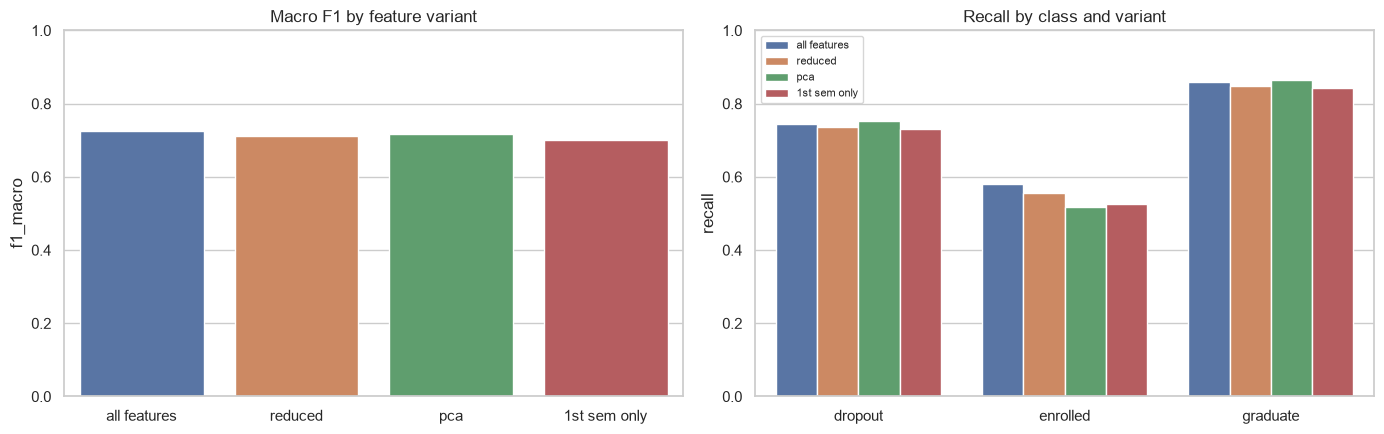

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
plot_data = forest_results[forest_results["model"] == "Random Forest"]

sns.barplot(data=plot_data, x="variant", y="f1_macro", hue="variant",
            legend=False, palette="deep", ax=axes[0])
axes[0].set_title("Macro F1 by feature variant")
axes[0].set_ylim(0, 1)
axes[0].set_xlabel("")

per_class = plot_data.melt(
    id_vars="variant",
    value_vars=["recall_dropout", "recall_enrolled", "recall_graduate"],
    var_name="class", value_name="recall",
)
per_class["class"] = per_class["class"].str.replace("recall_", "")
sns.barplot(data=per_class, x="class", y="recall", hue="variant",
            palette="deep", ax=axes[1])
axes[1].set_title("Recall by class and variant")
axes[1].set_ylim(0, 1)
axes[1].set_xlabel("")
axes[1].legend(fontsize=8)

fig.tight_layout()
fig.savefig(FIGURES / "04_rf_variants.png", dpi=150)
plt.show()

In [10]:
from sklearn.model_selection import cross_val_predict

# Confusion matrix for the best variant, from out-of-fold predictions.
best_variant = (
    forest_results[forest_results["model"] == "Random Forest"]
    .sort_values("f1_macro", ascending=False)
    .iloc[0]["variant"]
)
variant_key = {v: k for k, v in LABELS.items()}[best_variant]

pipeline = preprocess.build_pipeline(best_model(), variant=variant_key)
oof = cross_val_predict(pipeline, X_dev, y_dev, cv=CV)

print(f"best variant: {best_variant}\n")
matrix = ev.confusion_frame(y_dev, oof)
print(matrix)
print("\nrow percentages:")
print((matrix.div(matrix.sum(axis=1), axis=0) * 100).round(1))

best variant: all features

predicted  Dropout  Enrolled  Graduate
true                                  
Dropout        846       176       115
Enrolled       102       368       165
Graduate        52       197      1518

row percentages:
predicted  Dropout  Enrolled  Graduate
true                                  
Dropout       74.4      15.5      10.1
Enrolled      16.1      58.0      26.0
Graduate       2.9      11.1      85.9


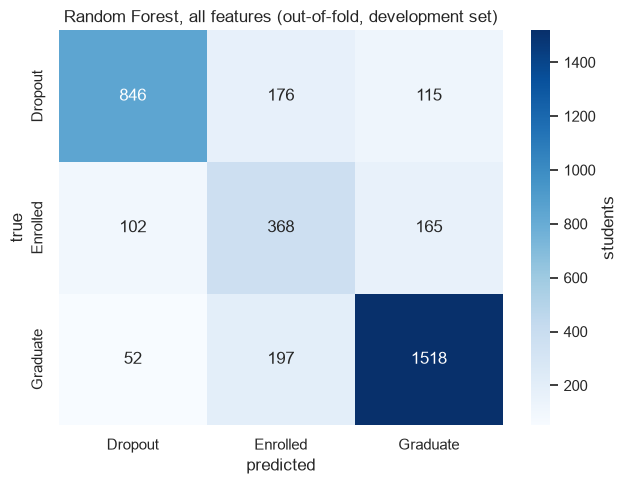

In [11]:
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(matrix, annot=True, fmt="d", cmap="Blues", cbar_kws={"label": "students"},
            ax=ax)
ax.set_title(f"Random Forest, {best_variant} (out-of-fold, development set)")
fig.tight_layout()
fig.savefig(FIGURES / "04_rf_confusion.png", dpi=150)
plt.show()

## 7. Which features the forest actually used

`feature_importances_` is the total reduction in Gini impurity attributable to each
feature, averaged over all 300 trees. It has a known bias: features with many possible
split points — continuous columns, and high-cardinality encodings — can accumulate
importance simply by offering more opportunities to split. The ranking is therefore read
as indicative, and checked against the statistical screening in notebook 02 and the
descriptor paper's own findings.

In [12]:
fitted = preprocess.build_pipeline(best_model(), variant="all").fit(X_dev, y_dev)
names = fitted.named_steps["prep"].get_feature_names_out()

importance = (
    pd.DataFrame({
        "feature": names,
        "importance": fitted.named_steps["model"].feature_importances_,
    })
    .sort_values("importance", ascending=False)
    .reset_index(drop=True)
)

print("cumulative importance of the top features:")
for n in (5, 10, 20, 40):
    print(f"  top {n:2d}: {importance['importance'].head(n).sum():.3f}")
print(f"\nfeatures with effectively zero importance: "
      f"{int((importance['importance'] < 0.0005).sum())} of {len(importance)}")

importance.head(20)

cumulative importance of the top features:
  top  5: 0.359
  top 10: 0.540
  top 20: 0.765
  top 40: 0.878

features with effectively zero importance: 10 of 109


,feature,importance
0,approval_rate_2nd,0.095604
1,Curricular units 2nd sem (approved),0.072065
2,total_approved,0.070193
3,Curricular units 2nd sem (grade),0.061885
4,approval_rate_1st,0.059260
5,Curricular units 1st sem (grade),0.043355
6,Curricular units 1st sem (approved),0.037657
7,Tuition fees up to date,0.033618
8,Curricular units 2nd sem (evaluations),0.033529
9,Age at enrollment,0.033242


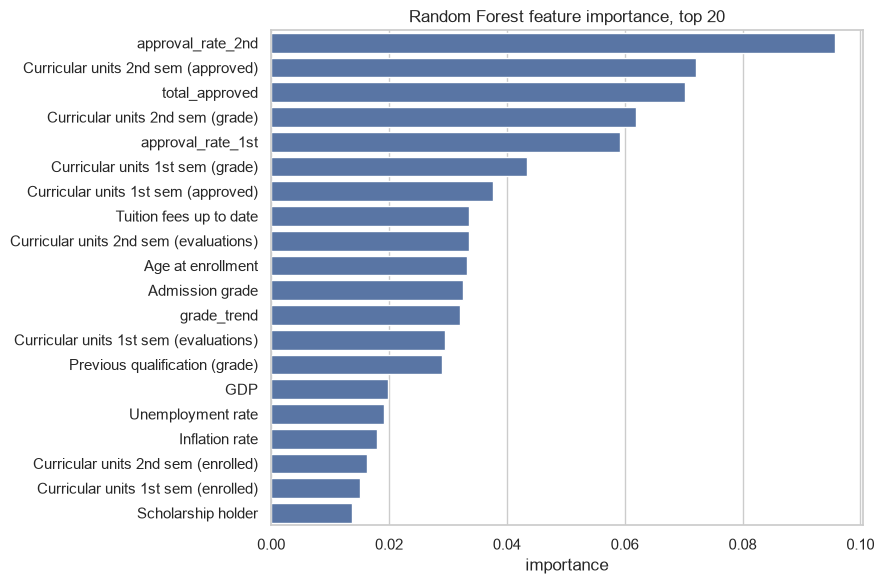

In [13]:
fig, ax = plt.subplots(figsize=(9, 6))
sns.barplot(data=importance.head(20), y="feature", x="importance",
            color="#4C72B0", ax=ax)
ax.set_title("Random Forest feature importance, top 20")
ax.set_ylabel("")
fig.tight_layout()
fig.savefig(FIGURES / "04_rf_importance.png", dpi=150)
plt.show()

In [14]:
# Does the forest agree with the statistical screening and with the paper?
paper_important = [
    "Curricular units 2nd sem (approved)",
    "Curricular units 1st sem (approved)",
    "Curricular units 2nd sem (grade)",
    "Course",
    "Tuition fees up to date",
]

importance["rank"] = importance["importance"].rank(ascending=False).astype(int)
print("the paper's five features, as ranked by the forest:\n")
for name in paper_important:
    hits = importance[importance["feature"].str.startswith(name)]
    if hits.empty:
        print(f"  {name:40s} not present")
    else:
        row = hits.iloc[0]
        print(f"  {name:40s} rank {row['rank']:3d}  importance {row['importance']:.4f}")

print("\nthe four engineered features:\n")
for name in data.ENGINEERED:
    row = importance[importance["feature"] == name].iloc[0]
    print(f"  {name:40s} rank {row['rank']:3d}  importance {row['importance']:.4f}")

the paper's five features, as ranked by the forest:

  Curricular units 2nd sem (approved)      rank   2  importance 0.0721
  Curricular units 1st sem (approved)      rank   7  importance 0.0377
  Curricular units 2nd sem (grade)         rank   4  importance 0.0619
  Course                                   rank  35  importance 0.0046
  Tuition fees up to date                  rank   8  importance 0.0336

the four engineered features:

  approval_rate_1st                        rank   5  importance 0.0593
  approval_rate_2nd                        rank   1  importance 0.0956
  grade_trend                              rank  12  importance 0.0320
  total_approved                           rank   3  importance 0.0702


## 8. How early can a warning be issued?

The `first_sem` variant withholds every second-semester column. This is a question about
**feature availability**, not leakage: second-semester results are genuine predictors,
but they do not exist until a student is most of a year into the course, by which point
an intervention has far less time to work.

Comparing it against `all` measures what accuracy costs to act a semester sooner.

In [15]:
early = forest_results[forest_results["variant"].isin(["all features", "1st sem only"])]
early_view = early.set_index("variant")[
    ["accuracy", "balanced_accuracy", "f1_macro", "mcc", "roc_auc",
     "recall_dropout", "recall_enrolled", "recall_graduate"]
].round(4)

print(early_view.T)

delta = early_view.loc["1st sem only"] - early_view.loc["all features"]
print("\ncost of dropping the second semester:")
print(delta.round(4).to_string())

variant            all features  1st sem only
accuracy                 0.7720        0.7499
balanced_accuracy        0.7276        0.6997
f1_macro                 0.7261        0.7003
mcc                      0.6323        0.5944
roc_auc                  0.8911        0.8715
recall_dropout           0.7441        0.7300
recall_enrolled          0.5795        0.5260
recall_graduate          0.8591        0.8432

cost of dropping the second semester:
accuracy            -0.0221
balanced_accuracy   -0.0279
f1_macro            -0.0258
mcc                 -0.0379
roc_auc             -0.0196
recall_dropout      -0.0141
recall_enrolled     -0.0535
recall_graduate     -0.0159


## 9. Summary

Everything above is cross-validated on the development set. The test set has not been
touched, and the final numbers for the report come from notebook 05.

In [16]:
summary = forest_results[forest_results["model"] == "Random Forest"].copy()
summary = summary.sort_values("f1_macro", ascending=False)

print("Random Forest, 5-fold cross-validation on 3,539 development rows\n")
print(summary.set_index("variant")[
    ["f1_macro", "balanced_accuracy", "mcc", "recall_dropout", "recall_enrolled"]
].round(4).to_string())

out = ROOT / "data" / "processed" / "rf_cv_results.csv"
forest_results.to_csv(out, index=False)
print(f"\nwritten to {out.relative_to(ROOT)}")

assert len(X_test) == 885, "test set must remain untouched"
print("test set still sealed:", len(X_test), "rows")

Random Forest, 5-fold cross-validation on 3,539 development rows

              f1_macro  balanced_accuracy     mcc  recall_dropout  recall_enrolled
variant                                                                           
all features    0.7261             0.7276  0.6323          0.7441           0.5795
pca             0.7158             0.7123  0.6196          0.7529           0.5181
reduced         0.7122             0.7138  0.6143          0.7361           0.5559
1st sem only    0.7003             0.6997  0.5944          0.7300           0.5260

written to data/processed/rf_cv_results.csv
test set still sealed: 885 rows
